# Environment_IREC_Launch_Site
Creates the RocketPy **`Environment`** object `env`: launch site location, gravity, and the atmosphere (air density, temperature, pressure, speed of sound and wind at every altitude). Every value comes from `25_26_MoS_Parameters`.

### How this notebook loads its inputs
This notebook doesn't redefine any numbers; it reads them from the notebooks it depends on.
- **Opened on its own:** the cell below runs its dependencies with IPython's `%run` (written as `get_ipython().run_line_magic("run", ...)` because the call sits inside an `if`). When `%run` runs a notebook it executes in the **same namespace**, so every variable it defines becomes available here.
- **Run from `Test_Flight_MoS`:** that notebook sets `PIPELINE = True` and has already loaded everything, so this cell skips the reload. `SHOW_INFO` turns off the `.info()` printouts and plots so the test flight output stays clean.

In [ ]:
from rocketpy import Rocket, SolidMotor, Environment, Flight   # simulation classes
import numpy as np                                              # arrays and maths
import pandas as pd                                             # reading .xlsx data files
from datetime import datetime, timedelta                        # launch date for the forecast
import matplotlib.pyplot as plt                                 # plotting

In [2]:
# PIPELINE is set to True by Test_Flight_MoS before it runs this notebook.
#   True  -> dependencies are already loaded; skip the info printouts and plots
#   False -> this notebook was opened on its own, so load what it needs first
PIPELINE = globals().get("PIPELINE", False)
if not PIPELINE:
    get_ipython().run_line_magic("run", "25_26_MoS_Parameters.ipynb")   # load 25_26_MoS_Parameters
SHOW_INFO = not PIPELINE   # only print .info() / draw plots when run on its own

## Launch site and date
- **`Environment(latitude, longitude, elevation)`:** sets the location. Latitude also sets gravity (RocketPy varies it with latitude and altitude) and the Earth model used to convert positions to latitude and longitude.
- **`set_date`:** takes a UTC time `(year, month, day, hour)`. It picks which forecast time to use, so it has to be set before the atmosphere.

In [3]:
env = Environment(
    latitude=LAUNCH_LAT,        # deg N
    longitude=LAUNCH_LON,       # deg E
    elevation=LAUNCH_ELEVATION  # m ASL (GFS replaces this with its own ground height)
    )

env.set_date(
    (LAUNCH_DATE.year, LAUNCH_DATE.month, LAUNCH_DATE.day, LAUNCH_HOUR_UTC)   # UTC
)

## Atmospheric model
- **`"Forecast"` with `file="GFS"`:** downloads NOAA's Global Forecast System profile above the site. Wind changes with altitude, which affects how far the rocket weathercocks and drifts. Use this to see how the rocket would fly on a real day.
- **`"standard_atmosphere"`:** the International Standard Atmosphere with **no wind**. It gives a repeatable baseline and is what DTEG 10.2.3 requires for the stability results.

Switch between them with `ATMOSPHERE_MODEL` in the parameters notebook.


Gravity Details

Acceleration of gravity at surface level:    9.7922 m/s²
Acceleration of gravity at  78.851 km (ASL): 9.5560 m/s²


Launch Site Details

Launch Date: 2026-11-04 12:00:00 UTC
Launch Site Latitude: 31.99000°
Launch Site Longitude: -102.07000°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 209929.28 W    3543446.67 N
Launch Site UTM zone: 13R
Launch Site Surface Elevation: 851.2 m


Atmospheric Model Details

Atmospheric Model Type: Forecast
Forecast Maximum Height: 78.851 km
Forecast Time Period: from 2026-10-28 00:00:00 to 2026-11-19 18:00:00 utc
Forecast Hour Interval: 3 hrs
Forecast Latitude Range: From 90.0° to -90.0°
Forecast Longitude Range: From 0.0° to 359.75°

Surface Atmospheric Conditions

Surface Wind Speed: 3.82 m/s
Surface Wind Direction: 132.79°
Surface Wind Heading: 312.79°
Surface Pressure: 918.85 hPa
Surface Temperature: 285.38 K
Surface Air Density: 1.122 kg/m³
Surface Speed of Sound: 338.65 m/s


Earth Model Details

Earth Radius at Launch 

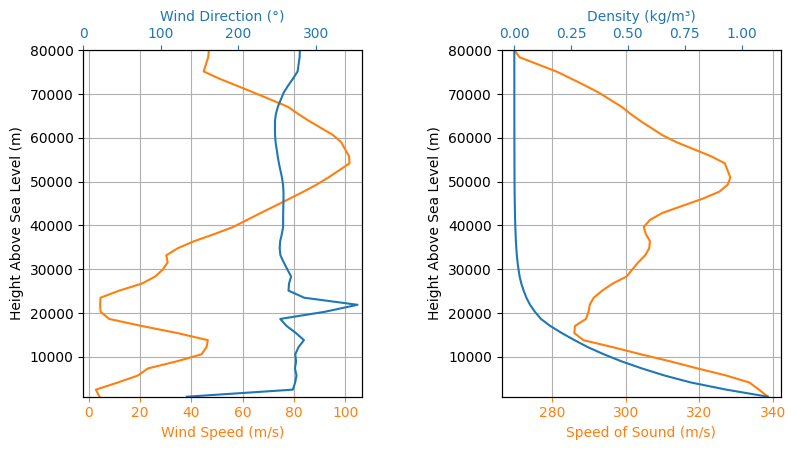

In [4]:
if ATMOSPHERE_MODEL == "Forecast":
    env.set_atmospheric_model(
        type="Forecast",        # real weather forecast
        file="GFS"              # NOAA Global Forecast System
        )
else:
    env.set_atmospheric_model(type=ATMOSPHERE_MODEL)   # e.g. "standard_atmosphere" (no wind)

if SHOW_INFO:
    env.info()                  # site summary + wind/temperature/density profiles